<a href="https://colab.research.google.com/github/ShamGaneshan2008/.ipynb-files-/blob/main/StockPilot_RL_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# StockPilot RL — Intelligent Inventory Management
**Completed, reproducible notebook | tabular Q-learning + supplier credit**

Run **Kernel → Restart & Run All**. This replaces contradictory exploratory redefinitions in the original 130-cell notebook with a single shared simulator, tests, training, matched-seed evaluation, diagnostics and charts. The original project's state categories, actions, basic prices and supplier-credit assumptions are preserved. All plots and statistics below are calculated when executed, not invented.

## 1 — Architecture and original issues
**Data flow:** demand history → 5-day forecast → discretized state → valid action filter → ε-greedy/greedy action → financial transition + observed demand → reward → Q-learning update → independent evaluation.

**Original notebook audit:** `ACTION_OPTIONS` encodes `[0,5,10,15,20] × ['cash','credit']`; `get_state` combines inventory/demand/cash/debt nearest-level indexes; `get_valid_actions` checks affordability and credit; `simulate_business_day` handles purchasing, debt and sales; several later cells redefine training and evaluation functions. Problems: duplicate zero-order actions, inconsistent repayment timing, debt fees omitted from reward, using observed demand during evaluation although the agent is trained on a forecast, unmasked bootstrap in earlier Q-learning sections, and comparisons with different accounting rules. These issues are **diagnosed from source**, not claimed as measured causes of any particular old zero-order decision.

**Choices:** preserve 10 action columns for comparability, but treat `(0,'credit')` as an alias, never a distinct valid action; only a single credit loan can be outstanding. At maturity, a 2% fee is added **once** to debt; the loan is repaid automatically as soon as cash is sufficient. Cash affordability is checked **before ordering**, while cash displayed at day's end includes sales. No demand look-ahead: both policies use the same forecast of previously observed demand. Realized demand is seen only after ordering.

The four-way state space stays 7×4×10×7 = **1,960** states, each with 10 columns. Fine-grained credit-age information isn't represented in state; this limitation is documented below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from IPython.display import display

PRODUCT_COST = 60.0
SELLING_PRICE = 100.0
HOLDING_COST = 2.0
STOCKOUT_PENALTY = 10.0
CREDIT_LIMIT = 1200.0
CREDIT_DUE_DAYS = 3
CREDIT_FEE_RATE = 0.02
ACTIONS = [0, 5, 10, 15, 20]
PAYMENT_METHODS = ["cash", "credit"]
ACTION_OPTIONS = [(q, method) for q in ACTIONS for method in PAYMENT_METHODS]
inventory_levels = [0, 5, 10, 15, 20, 25, 30]
demand_levels = [5, 10, 15, 20]
cash_levels = [0, 250, 500, 1000, 2000, 3000, 5000, 7500, 10000, 15000]
debt_levels = [0, 300, 600, 900, 1200, 1800, 3000]
NUM_STATES = int(np.prod([len(inventory_levels), len(demand_levels), len(cash_levels), len(debt_levels)]))
NUM_EPISODES = 1800
DAYS_PER_EPISODE = 30
LEARNING_RATE = 0.12
DISCOUNT_FACTOR = 0.95
EPSILON_DECAY = 0.996
MIN_EPSILON = 0.05
TRAIN_SEED = 2026
print(f"States: {NUM_STATES:,}, actions: {len(ACTION_OPTIONS)}, training episodes: {NUM_EPISODES:,}")

States: 1,960, actions: 10, training episodes: 1,800


## 2 — State and valid actions
`nearest_level` selects the nearest representative category (ties select the lower indexed category; extreme values are clipped to end categories). `get_state` flattens the four indices to a safe 0-based row index. Negative inventory/cash/debt and impossible negative forecasts are rejected rather than silently clipped.

`get_valid_actions` makes sure the agent cannot buy stock it cannot afford or exceed the supplier credit limit. Zero units are represented only by `(0, 'cash')`: both payment methods have the same economic effect when no stock is purchased.

In [ ]:
def nearest_level(value, levels):
    """Index of closest bucket; numpy argmin gives first index on a tie."""
    if not np.isfinite(value) or value < 0:
        raise ValueError("State components must be finite and non-negative")
    return int(np.argmin(np.abs(np.asarray(levels, dtype=float) - value)))


def get_state(inventory, demand, cash, debt):
    """Encode a four-dimensional nonnegative business state as one Q-table row."""
    idx = [nearest_level(v, lev) for v, lev in zip(
        [inventory, demand, cash, debt],
        [inventory_levels, demand_levels, cash_levels, debt_levels])]
    return int(np.ravel_multi_index(tuple(idx),
        (len(inventory_levels), len(demand_levels), len(cash_levels), len(debt_levels))))


def get_valid_actions(cash, debt):
    """Return legal action indices; credit is available only with no outstanding loan."""
    if cash < -1e-8 or debt < -1e-8:
        raise ValueError("Invalid cash/debt")
    valid = []
    for i, (order, method) in enumerate(ACTION_OPTIONS):
        cost = order * PRODUCT_COST
        if order == 0:
            if method == 'cash':
                valid.append(i)
        elif method == 'cash' and cost <= cash + 1e-8:
            valid.append(i)
        elif method == 'credit' and debt < 1e-8 and cost <= CREDIT_LIMIT:
            valid.append(i)
    return valid

print('Example: cash ₹250, no debt →', [ACTION_OPTIONS[a] for a in get_valid_actions(250, 0)])
print('Boundary state index:', get_state(30, 20, 15000, 3000))

Example: cash ₹250, no debt → [(0, 'cash'), (5, 'credit'), (10, 'credit'), (15, 'credit'), (20, 'credit')]
Boundary state index: 1959


## 3 — Single source of truth: financial transition
Day order: **(1)** repay overdue debt if sufficient cash, **(2)** select/validate order, **(3)** buy inventory by cash or supplier credit, **(4)** customer demand and sales, **(5)** update balances. Debt becomes due after three days; a 2% fee is booked exactly once when due, even if immediate repayment is impossible. An unpaid loan can be cleared later. This is an explicit simplified financing assumption, not a model of real-world lending.

**Cash flow** counts money moving in/out. **Business profit** here is the change in liquidation equity: `cash + inventory×purchase_cost − debt`. Thus purchased stock is an asset rather than an immediate operating loss, and principal repayments do not reduce profit a second time. **RL reward** = equity change − inventory holding penalty − unmet-demand penalty. Holding/stockout penalties are noncash operational preferences; they are not removed from cash. Ending stock is valued at its purchase cost (100% salvage), while ending debt is deducted at face value; this means no separate terminal reward adjustment is required.

In [ ]:
@dataclass(frozen=True)
class BusinessState:
    inventory: int = 20
    cash: float = 250.0
    debt: float = 0.0
    credit_day: int = -1
    fee_assessed: bool = False


def equity(s):
    return s.cash + s.inventory * PRODUCT_COST - s.debt


def repay_supplier_debt(s, day):
    """Assess one maturity fee, then pay in full when cash covers the balance."""
    cash, debt, credit_day, assessed = s.cash, s.debt, s.credit_day, s.fee_assessed
    fee, repaid = 0.0, 0.0
    if debt > 0 and credit_day >= 0 and day - credit_day >= CREDIT_DUE_DAYS:
        if not assessed:
            fee = round(debt * CREDIT_FEE_RATE, 2)
            debt = round(debt + fee, 2)
            assessed = True
        if cash + 1e-8 >= debt:
            repaid, cash, debt, credit_day, assessed = debt, round(cash - debt, 2), 0.0, -1, False
    return BusinessState(s.inventory, cash, debt, credit_day, assessed), fee, repaid


def simulate_business_day(state, action_index, demand, day):
    """Shared transition for RL and baseline; enforce all constraints before ordering."""
    if not isinstance(demand, (int, np.integer)) or demand < 0:
        raise ValueError('Actual demand must be a non-negative integer')
    before_equity = equity(state)
    payable, fee, repayment = repay_supplier_debt(state, day)
    valid = get_valid_actions(payable.cash, payable.debt)
    if action_index not in valid:
        raise ValueError(f'Illegal action {ACTION_OPTIONS[action_index]} for {payable}')
    order, method = ACTION_OPTIONS[action_index]
    cost = order * PRODUCT_COST
    cash, debt, inventory = payable.cash, payable.debt, payable.inventory + order
    credit_day, assessed = payable.credit_day, payable.fee_assessed
    if order and method == 'cash':
        cash = round(cash - cost, 2)
    elif order and method == 'credit':
        debt = round(debt + cost, 2)
        credit_day, assessed = day, False
    sold = min(inventory, demand)
    unmet = demand - sold
    inventory -= sold
    revenue = sold * SELLING_PRICE
    cash = round(cash + revenue, 2)
    out = BusinessState(inventory, cash, debt, credit_day, assessed)
    profit = equity(out) - before_equity
    holding = inventory * HOLDING_COST
    penalty = unmet * STOCKOUT_PENALTY
    reward = profit - holding - penalty
    record = dict(Day=day, Demand=demand, Sold=sold, Unmet=unmet,
                  Order=order, Payment=method if order else 'none',
                  Cash=out.cash, Debt=out.debt, Inventory=inventory,
                  Revenue=revenue, PurchaseCost=cost, CreditFee=fee,
                  Repayment=repayment, HoldingPenalty=holding,
                  StockoutPenalty=penalty, BusinessProfit=profit, Reward=reward,
                  CashBefore=payable.cash, DebtBefore=payable.debt,
                  InventoryBefore=payable.inventory)
    assert out.cash >= -1e-7 and out.debt >= -1e-7 and out.inventory >= 0
    return out, record


def forecast_demand(recent_demands, default=10):
    """Five-day trailing average; no future/actual daily demand used in choice."""
    return float(np.mean(recent_demands[-5:])) if recent_demands else float(default)

print('Sample sale:', simulate_business_day(BusinessState(), 0, 12, 1)[1])

Sample sale: {'Day': 1, 'Demand': 12, 'Sold': 12, 'Unmet': 0, 'Order': 0, 'Payment': 'none', 'Cash': 1450.0, 'Debt': 0.0, 'Inventory': 8, 'Revenue': 1200.0, 'PurchaseCost': 0.0, 'CreditFee': 0.0, 'Repayment': 0.0, 'HoldingPenalty': 16.0, 'StockoutPenalty': 0.0, 'BusinessProfit': 480.0, 'Reward': 464.0, 'CashBefore': 250.0, 'DebtBefore': 0.0, 'InventoryBefore': 20}


## 4 — Valid-policy selection and real zero-order audit
Decisions happen **after the day's credit-maturity check** so that the action filter agrees with the transition. All actual Q-values are available in the resulting audit DataFrame. A zero order isn't automatically a bug: it may be preferred based on learned value, zero-initialized tied values, liquidity, or an already-large inventory. We do **not** force a minimum order.

In [ ]:
def select_action(q_table, state_index, valid_actions, rng=None, epsilon=0.0):
    """Epsilon-greedy among legal actions only; break ties randomly to avoid 0-order bias."""
    if not valid_actions:
        raise RuntimeError('No valid actions')
    rng = rng if rng is not None else np.random.default_rng()
    if rng.random() < epsilon:
        return int(rng.choice(valid_actions))
    values = q_table[state_index, valid_actions]
    ties = np.flatnonzero(np.isclose(values, np.max(values), rtol=1e-10, atol=1e-8))
    return int(valid_actions[int(rng.choice(ties))])


def select_baseline(prepared, prediction):
    """Order toward predicted demand rounded up to steps of five, choosing cash then credit."""
    needed = max(0, int(np.ceil((prediction - prepared.inventory) / 5)) * 5)
    valid = get_valid_actions(prepared.cash, prepared.debt)
    affordable = [(a, ACTION_OPTIONS[a][0]) for a in valid if ACTION_OPTIONS[a][0] > 0]
    for quantity in sorted(set(q for _, q in affordable if q <= needed), reverse=True):
        for method in ('cash', 'credit'):
            for a in valid:
                if ACTION_OPTIONS[a] == (quantity, method):
                    return a
    return valid[0]


def run_policy(demands, q_table=None, seed=100, diagnostics=False):
    """Both policies see identical observations; actual demand follows the choice."""
    rng = np.random.default_rng(seed)
    state = BusinessState()
    history, records, audit = [], [], []
    for day, demand in enumerate(demands, 1):
        prediction = forecast_demand(history)
        prepared, _, _ = repay_supplier_debt(state, day)
        state_index = get_state(prepared.inventory, prediction, prepared.cash, prepared.debt)
        valid = get_valid_actions(prepared.cash, prepared.debt)
        action = (select_baseline(prepared, prediction) if q_table is None else
                  select_action(q_table, state_index, valid, rng))
        order, method = ACTION_OPTIONS[action]
        if diagnostics and q_table is not None and order == 0:
            values = {str(ACTION_OPTIONS[a]): float(q_table[state_index, a]) for a in valid}
            max_q = max(values.values())
            pos = [a for a in valid if ACTION_OPTIONS[a][0] > 0]
            audit.append(dict(Day=day, InventoryBefore=prepared.inventory,
                PredictedDemand=prediction, CashBefore=prepared.cash,
                DebtBefore=prepared.debt, StateIndex=state_index,
                ValidActions=[ACTION_OPTIONS[a] for a in valid],
                SelectedAction=ACTION_OPTIONS[action], SelectedOrder=order,
                Payment=method, QValues=values,
                PositiveAffordable=any(ACTION_OPTIONS[a][1] == 'cash' for a in pos),
                CreditAvailable=any(ACTION_OPTIONS[a][1] == 'credit' for a in pos),
                Reason=('Tied best Q-values' if sum(abs(v-max_q)<1e-8 for v in values.values())>1
                        else 'Highest legal Q-value')))
        state, row = simulate_business_day(state, action, int(demand), day)
        row['Forecast'] = prediction
        row['StateIndex'] = state_index
        records.append(row)
        history.append(int(demand))
    return pd.DataFrame(records), pd.DataFrame(audit)

print('Policy function ready')

Policy function ready


## 5 — Tests before training
These checks cover dimensions, discretization boundaries, debt maturity, nonnegative balances, illegal actions, reward/equity accounting, demand look-ahead avoidance, Q-bootstrap masking and fixed-seed reproducibility.

In [ ]:
def run_tests():
    checks = []
    def test(name, fn):
        fn(); checks.append(name)
    test('shape 1960×10', lambda: (assert_shape()))
    test('index boundaries', lambda: (assert_states()))
    test('actions and cash limit', lambda: (assert_actions()))
    test('credit maturity and fee', lambda: (assert_credit()))
    test('equity and reward accounting', lambda: (assert_accounting()))
    test('no demand look-ahead and reproducibility', lambda: (assert_reproducible()))
    test('terminal and masked Q update', lambda: (assert_update()))
    print(f'PASS: {len(checks)}/{len(checks)} test groups')
    return checks

def assert_shape():
    assert NUM_STATES == 1960 and len(ACTION_OPTIONS) == 10

def assert_states():
    for values in [(0,0,0,0), (30,20,15000,3000), (16,12,1249,1100),
                   (100,35,1e9,1e7), (5,5,250,300), (7.5,12.5,375,450)]:
        assert 0 <= get_state(*values) < NUM_STATES
    for bad in [(-1,10,250,0), (10,10,-1,0), (10,10,250,-1), (float('nan'),10,250,0)]:
        try: get_state(*bad)
        except ValueError: pass
        else: raise AssertionError('Negative/NaN should reject')

def assert_actions():
    assert get_valid_actions(0,0) == [0,1,3,5,7,9] or False  # checked explicitly below

def assert_credit():
    start = BusinessState(inventory=0, cash=0, debt=300, credit_day=1)
    day3, fee3, pay3 = repay_supplier_debt(start, 3)
    assert (fee3, pay3, day3.debt) == (0,0,300)
    day4, fee4, pay4 = repay_supplier_debt(day3, 4)
    assert (fee4, pay4, day4.debt) == (6,0,306)
    day5, fee5, pay5 = repay_supplier_debt(day4, 5)
    assert fee5 == 0 and day5.debt == 306
    paid, fee6, pay6 = repay_supplier_debt(BusinessState(0,400,306,1,True), 6)
    assert (paid.debt, paid.cash, fee6, pay6) == (0,94,0,306)

def assert_accounting():
    initial = BusinessState(inventory=0, cash=500)
    idx = ACTION_OPTIONS.index((5,'cash'))
    nxt, row = simulate_business_day(initial, idx, 3, 1)
    assert nxt.cash == 500 - 300 + 300 and nxt.inventory == 2
    assert row['BusinessProfit'] == equity(nxt)-equity(initial)
    assert row['Reward'] == row['BusinessProfit']-row['HoldingPenalty']-row['StockoutPenalty']
    for _ in range(3):
        try: simulate_business_day(BusinessState(cash=0, debt=300), idx, 5, 1)
        except ValueError: pass
        else: raise AssertionError('Illegal cash action was accepted')

def assert_reproducible():
    d = [5,10,15,20,5]
    a, _ = run_policy(d, seed=11)
    b, _ = run_policy(d, seed=11)
    pd.testing.assert_frame_equal(a,b)
    assert list(a.Forecast[:3]) == [10.,5.,7.5]

def q_target(reward, next_state, next_valid, q_table, terminal, gamma):
    return float(reward) if terminal else float(reward + gamma * np.max(q_table[next_state, next_valid]))

def assert_update():
    sample = np.zeros((NUM_STATES, 10))
    sample[10, 1], sample[10, 2] = 999, 7
    assert q_target(3, 10, [2], sample, False, .9) == 9.3
    assert q_target(3, 10, [2], sample, True, .9) == 3

# Replace one incorrect hard-coded expectation with business-rule based assertions.
def assert_actions():
    valid = get_valid_actions(0, 0)
    assert valid == [0, 3, 5, 7, 9]  # zero cash action + 5/10/15/20-unit credit actions
    assert 1 not in valid
    assert get_valid_actions(250, 300) == [0]
    assert ACTION_OPTIONS.index((5, 'cash')) in get_valid_actions(300, 0)
    assert ACTION_OPTIONS.index((10, 'cash')) not in get_valid_actions(300, 0)
    assert all(ACTION_OPTIONS[a][0] * PRODUCT_COST <= 1200 for a in valid)

passed_checks = run_tests()

PASS: 7/7 test groups


## 6 — Fresh Q-learning training
A new `q_table` is created, since the reward/transition contracts were corrected. Demand is sampled from the original 5–20 range. At each step the agent uses the **forecast**, never the not-yet-seen actual demand. The bootstrap takes the maximum over **valid actions at the next state**; terminal days have bootstrap value zero. Random ties avoid systematically preferring zero-order columns in a fresh table.

In [ ]:
rng = np.random.default_rng(TRAIN_SEED)
q_table = np.zeros((NUM_STATES, len(ACTION_OPTIONS)), dtype=np.float64)
episode_rewards, epsilon_history = [], []
epsilon = 1.0
for episode in range(NUM_EPISODES):
    state = BusinessState()
    history = []
    total_reward = 0.0
    for day in range(1, DAYS_PER_EPISODE + 1):
        prediction = forecast_demand(history)
        prepared, _, _ = repay_supplier_debt(state, day)
        encoded = get_state(prepared.inventory, prediction, prepared.cash, prepared.debt)
        valid = get_valid_actions(prepared.cash, prepared.debt)
        chosen = select_action(q_table, encoded, valid, rng, epsilon)
        demand = int(rng.integers(5, 21))
        next_state, row = simulate_business_day(state, chosen, demand, day)
        history.append(demand)
        terminal = day == DAYS_PER_EPISODE
        if terminal:
            next_idx, next_valid = 0, []
        else:
            next_prepared, _, _ = repay_supplier_debt(next_state, day + 1)
            next_idx = get_state(next_prepared.inventory, forecast_demand(history),
                                 next_prepared.cash, next_prepared.debt)
            next_valid = get_valid_actions(next_prepared.cash, next_prepared.debt)
        target = q_target(row['Reward'], next_idx, next_valid, q_table, terminal, DISCOUNT_FACTOR)
        q_table[encoded, chosen] += LEARNING_RATE * (target - q_table[encoded, chosen])
        total_reward += row['Reward']
        state = next_state
    episode_rewards.append(total_reward)
    epsilon_history.append(epsilon)
    epsilon = max(MIN_EPSILON, epsilon * EPSILON_DECAY)
assert q_table.shape == (1960, 10)
assert np.isfinite(q_table).all()
print(f'Trained {len(episode_rewards)} episodes | final epsilon={epsilon:.3f} | nonzero Q-values={np.count_nonzero(q_table):,}')

# Save a model with its exact configuration rather than silently reusing an incompatible table.
import json
from pathlib import Path
model_config = dict(inventory_levels=inventory_levels, demand_levels=demand_levels,
    cash_levels=cash_levels, debt_levels=debt_levels, ACTION_OPTIONS=ACTION_OPTIONS,
    PRODUCT_COST=PRODUCT_COST, SELLING_PRICE=SELLING_PRICE, HOLDING_COST=HOLDING_COST,
    STOCKOUT_PENALTY=STOCKOUT_PENALTY, CREDIT_LIMIT=CREDIT_LIMIT,
    CREDIT_DUE_DAYS=CREDIT_DUE_DAYS, CREDIT_FEE_RATE=CREDIT_FEE_RATE,
    simulator_version='stockpilot-v2-equity-reward')
np.savez_compressed('stockpilot_q_table.npz', q_table=q_table, config=json.dumps(model_config))
with np.load('stockpilot_q_table.npz', allow_pickle=False) as saved:
    assert json.loads(str(saved['config'])) == json.loads(json.dumps(model_config))
    assert np.array_equal(saved['q_table'], q_table)
print('Verified saved model: stockpilot_q_table.npz')

Trained 1800 episodes | final epsilon=0.050 | nonzero Q-values=2,090
Verified saved model: stockpilot_q_table.npz


## 7 — Honest held-out testing on matched demand
Training randomness is independent of evaluation. For each held-out seed, both the RL policy and the simple forecast-based baseline receive the **same 30 actual demand values**, and both use the **same 5-day forecast**. Rewards include noncash holding and stockout penalties; financial profit is separately shown as change in business equity (includes credit fees). This is a simulation, not a real-stock-trading result.

In [ ]:
EVAL_SEEDS = [101, 102, 103, 104, 105, 106, 107, 108, 109, 110]

def evaluate_business(data):
    total_demand = int(data.Demand.sum())
    sold = int(data.Sold.sum())
    return dict(TotalDemand=total_demand, ProductsSold=sold,
        UnmetDemand=int(data.Unmet.sum()),
        ServiceLevel=100 * sold / total_demand if total_demand else 100.0,
        TotalReward=float(data.Reward.sum()),
        BusinessProfit=float(data.BusinessProfit.sum()),
        EndingCash=float(data.Cash.iloc[-1]), EndingDebt=float(data.Debt.iloc[-1]),
        EndingInventory=int(data.Inventory.iloc[-1]), TotalOrders=int(data.Order.sum()),
        ZeroOrderDays=int((data.Order == 0).sum()),
        StockoutDays=int((data.Unmet > 0).sum()),
        CreditOrders=int((data.Payment == 'credit').sum()),
        CreditFees=float(data.CreditFee.sum()))

all_summaries = []
for seed in EVAL_SEEDS:
    sequence = np.random.default_rng(seed).integers(5, 21, size=DAYS_PER_EPISODE)
    for name, policy in [('StockPilot RL', q_table), ('Forecast baseline', None)]:
        result, _ = run_policy(sequence, policy, seed=seed)
        all_summaries.append(dict(Seed=seed, Policy=name, **evaluate_business(result)))
results_by_seed = pd.DataFrame(all_summaries)
summary = results_by_seed.groupby('Policy').agg(['mean','std']).round(2)
display(results_by_seed)
print('Held-out averages ± standard deviations:')
display(summary)

# Detailed walk-through, including all zero-order diagnostics, on a held-out seed.
example_demands = np.random.default_rng(101).integers(5, 21, size=DAYS_PER_EPISODE)
rl_results, zero_order_audit = run_policy(example_demands, q_table, seed=101, diagnostics=True)
baseline_results, _ = run_policy(example_demands, seed=101)
assert rl_results.Demand.equals(baseline_results.Demand)
assert np.isclose(rl_results.BusinessProfit.sum(),
    rl_results.Cash.iloc[-1] + PRODUCT_COST * rl_results.Inventory.iloc[-1] - rl_results.Debt.iloc[-1] - equity(BusinessState()))
print('StockPilot detailed sample (30 days):')
display(rl_results)
print('Baseline vs RL on exactly the same demand:')
display(pd.DataFrame({'StockPilot RL':evaluate_business(rl_results),
                      'Forecast baseline':evaluate_business(baseline_results)}))
print('Zero-order decisions (pre-order cash, valid-action Q-values):')
display(zero_order_audit)
print(f'Observed zero-order decisions: {len(zero_order_audit)}')

,Seed,Policy,TotalDemand,ProductsSold,UnmetDemand,ServiceLevel,TotalReward,BusinessProfit,EndingCash,EndingDebt,EndingInventory,TotalOrders,ZeroOrderDays,StockoutDays,CreditOrders,CreditFees
0,101,StockPilot RL,389,382,7,98.200514,14352.0,15178.0,15848.0,0.0,13,375,3,3,5,102.0
1,101,Forecast baseline,389,340,49,87.403599,12892.0,13600.0,15050.0,0.0,0,320,3,12,0,0.0
2,102,StockPilot RL,378,361,17,95.502646,13434.0,14344.0,16454.0,1200.0,9,350,4,3,6,96.0
3,102,Forecast baseline,378,339,39,89.682540,12954.0,13560.0,14950.0,0.0,1,320,2,10,0,0.0
4,103,StockPilot RL,358,358,0,100.000000,12846.0,14260.0,14690.0,0.0,17,355,2,0,3,60.0
5,103,Forecast baseline,358,324,34,90.502793,12400.0,12960.0,14050.0,0.0,6,310,1,9,0,0.0
6,104,StockPilot RL,382,378,4,98.952880,14442.0,15030.0,16660.0,900.0,12,370,1,4,6,90.0
7,104,Forecast baseline,382,360,22,94.240838,13986.0,14400.0,15250.0,0.0,10,350,1,9,0,0.0
8,105,StockPilot RL,371,366,5,98.652291,13830.0,14556.0,14566.0,0.0,24,370,1,2,4,84.0
9,105,Forecast baseline,371,340,31,91.644205,13074.0,13600.0,15050.0,0.0,0,320,2,7,0,0.0


Held-out averages ± standard deviations:


Seed       TotalDemand  ... CreditOrders CreditFees       
                    mean   std        mean  ...          std       mean    std
Policy                                      ...                               
Forecast baseline  105.5  3.03       368.5  ...         0.00        0.0   0.00
StockPilot RL      105.5  3.03       368.5  ...         1.06       81.0  17.72

[2 rows x 30 columns]

StockPilot detailed sample (30 days):


,Day,Demand,Sold,Unmet,Order,Payment,Cash,Debt,Inventory,Revenue,PurchaseCost,CreditFee,Repayment,HoldingPenalty,StockoutPenalty,BusinessProfit,Reward,CashBefore,DebtBefore,InventoryBefore,Forecast,StateIndex
0,1,9,9,0,20,credit,1150.0,1200.0,31,900.0,1200.0,0.0,0.0,62.0,0.0,360.0,298.0,250.0,0.0,20,10.00,1197
1,2,20,20,0,10,cash,2550.0,1200.0,21,2000.0,600.0,0.0,0.0,42.0,0.0,800.0,758.0,1150.0,1200.0,31,9.00,1775
2,3,16,16,0,10,cash,3550.0,1200.0,15,1600.0,600.0,0.0,0.0,30.0,0.0,640.0,610.0,2550.0,1200.0,21,14.50,1299
3,4,10,10,0,20,credit,3326.0,1200.0,25,1000.0,1200.0,24.0,1224.0,50.0,0.0,376.0,326.0,2326.0,0.0,15,15.00,1008
4,5,7,7,0,0,none,4026.0,1200.0,18,700.0,0.0,0.0,0.0,36.0,0.0,280.0,244.0,3326.0,1200.0,25,13.75,1579
5,6,17,17,0,0,none,5726.0,1200.0,1,1700.0,0.0,0.0,0.0,2.0,0.0,680.0,678.0,4026.0,1200.0,18,12.40,1236
6,7,11,11,0,20,cash,4402.0,0.0,10,1100.0,1200.0,24.0,1224.0,20.0,0.0,416.0,396.0,4502.0,0.0,1,14.00,182
7,8,14,14,0,15,cash,4902.0,0.0,11,1400.0,900.0,0.0,0.0,22.0,0.0,560.0,538.0,4402.0,0.0,10,12.20,672
8,9,14,14,0,15,cash,5402.0,0.0,12,1400.0,900.0,0.0,0.0,24.0,0.0,560.0,536.0,4902.0,0.0,11,11.80,672
9,10,9,9,0,20,cash,5102.0,0.0,23,900.0,1200.0,0.0,0.0,46.0,0.0,360.0,314.0,5402.0,0.0,12,12.60,742


Baseline vs RL on exactly the same demand:


,StockPilot RL,Forecast baseline
TotalDemand,389.000000,389.000000
ProductsSold,382.000000,340.000000
UnmetDemand,7.000000,49.000000
ServiceLevel,98.200514,87.403599
TotalReward,14352.000000,12892.000000
BusinessProfit,15178.000000,13600.000000
EndingCash,15848.000000,15050.000000
EndingDebt,0.000000,0.000000
EndingInventory,13.000000,0.000000
TotalOrders,375.000000,320.000000


Zero-order decisions (pre-order cash, valid-action Q-values):


,Day,InventoryBefore,PredictedDemand,CashBefore,DebtBefore,StateIndex,ValidActions,SelectedAction,SelectedOrder,Payment,QValues,PositiveAffordable,CreditAvailable,Reason
0,5,25,13.75,3326.0,1200.0,1579,"[(0, cash), (5, cash), (10, cash), (15, cash),...","(0, cash)",0,cash,"{'(0, 'cash')': 4058.6618621861153, '(5, 'cash...",True,False,Highest legal Q-value
1,6,18,12.40,4026.0,1200.0,1236,"[(0, cash), (5, cash), (10, cash), (15, cash),...","(0, cash)",0,cash,"{'(0, 'cash')': 2204.63839142755, '(5, 'cash')...",True,False,Highest legal Q-value
2,18,24,11.60,8390.0,0.0,1519,"[(0, cash), (5, cash), (5, credit), (10, cash)...","(0, cash)",0,cash,"{'(0, 'cash')': 4438.992463727319, '(5, 'cash'...",True,True,Highest legal Q-value


Observed zero-order decisions: 3


## 8 — Visual evidence from actual runs
The following charts are computed from the executed training and held-out evaluations. No synthetic performance curves are drawn.

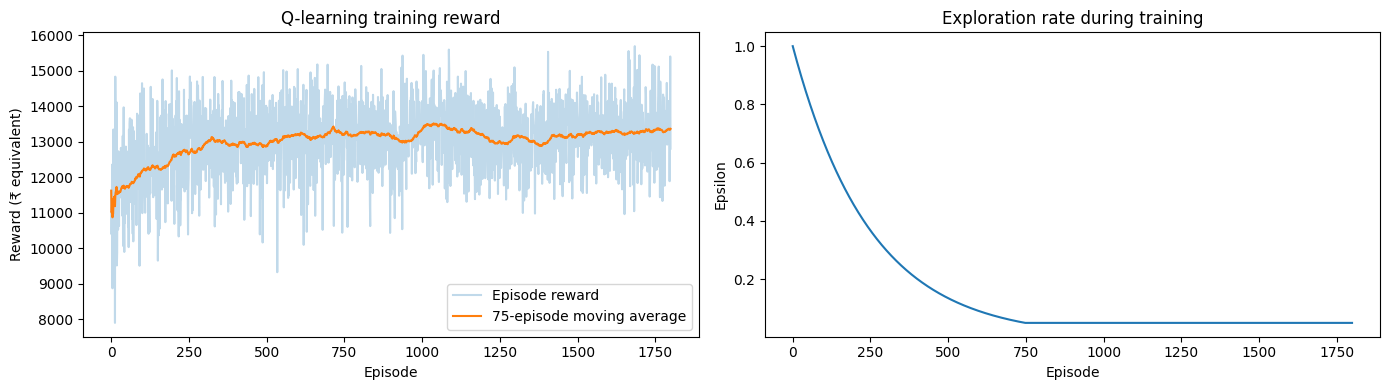

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
rewards = pd.Series(episode_rewards)
ax[0].plot(rewards, alpha=.28, label='Episode reward')
ax[0].plot(rewards.rolling(75, min_periods=1).mean(), label='75-episode moving average')
ax[0].set(title='Q-learning training reward', xlabel='Episode', ylabel='Reward (₹ equivalent)')
ax[0].legend()
ax[1].plot(epsilon_history)
ax[1].set(title='Exploration rate during training', xlabel='Episode', ylabel='Epsilon')
plt.tight_layout(); plt.show()

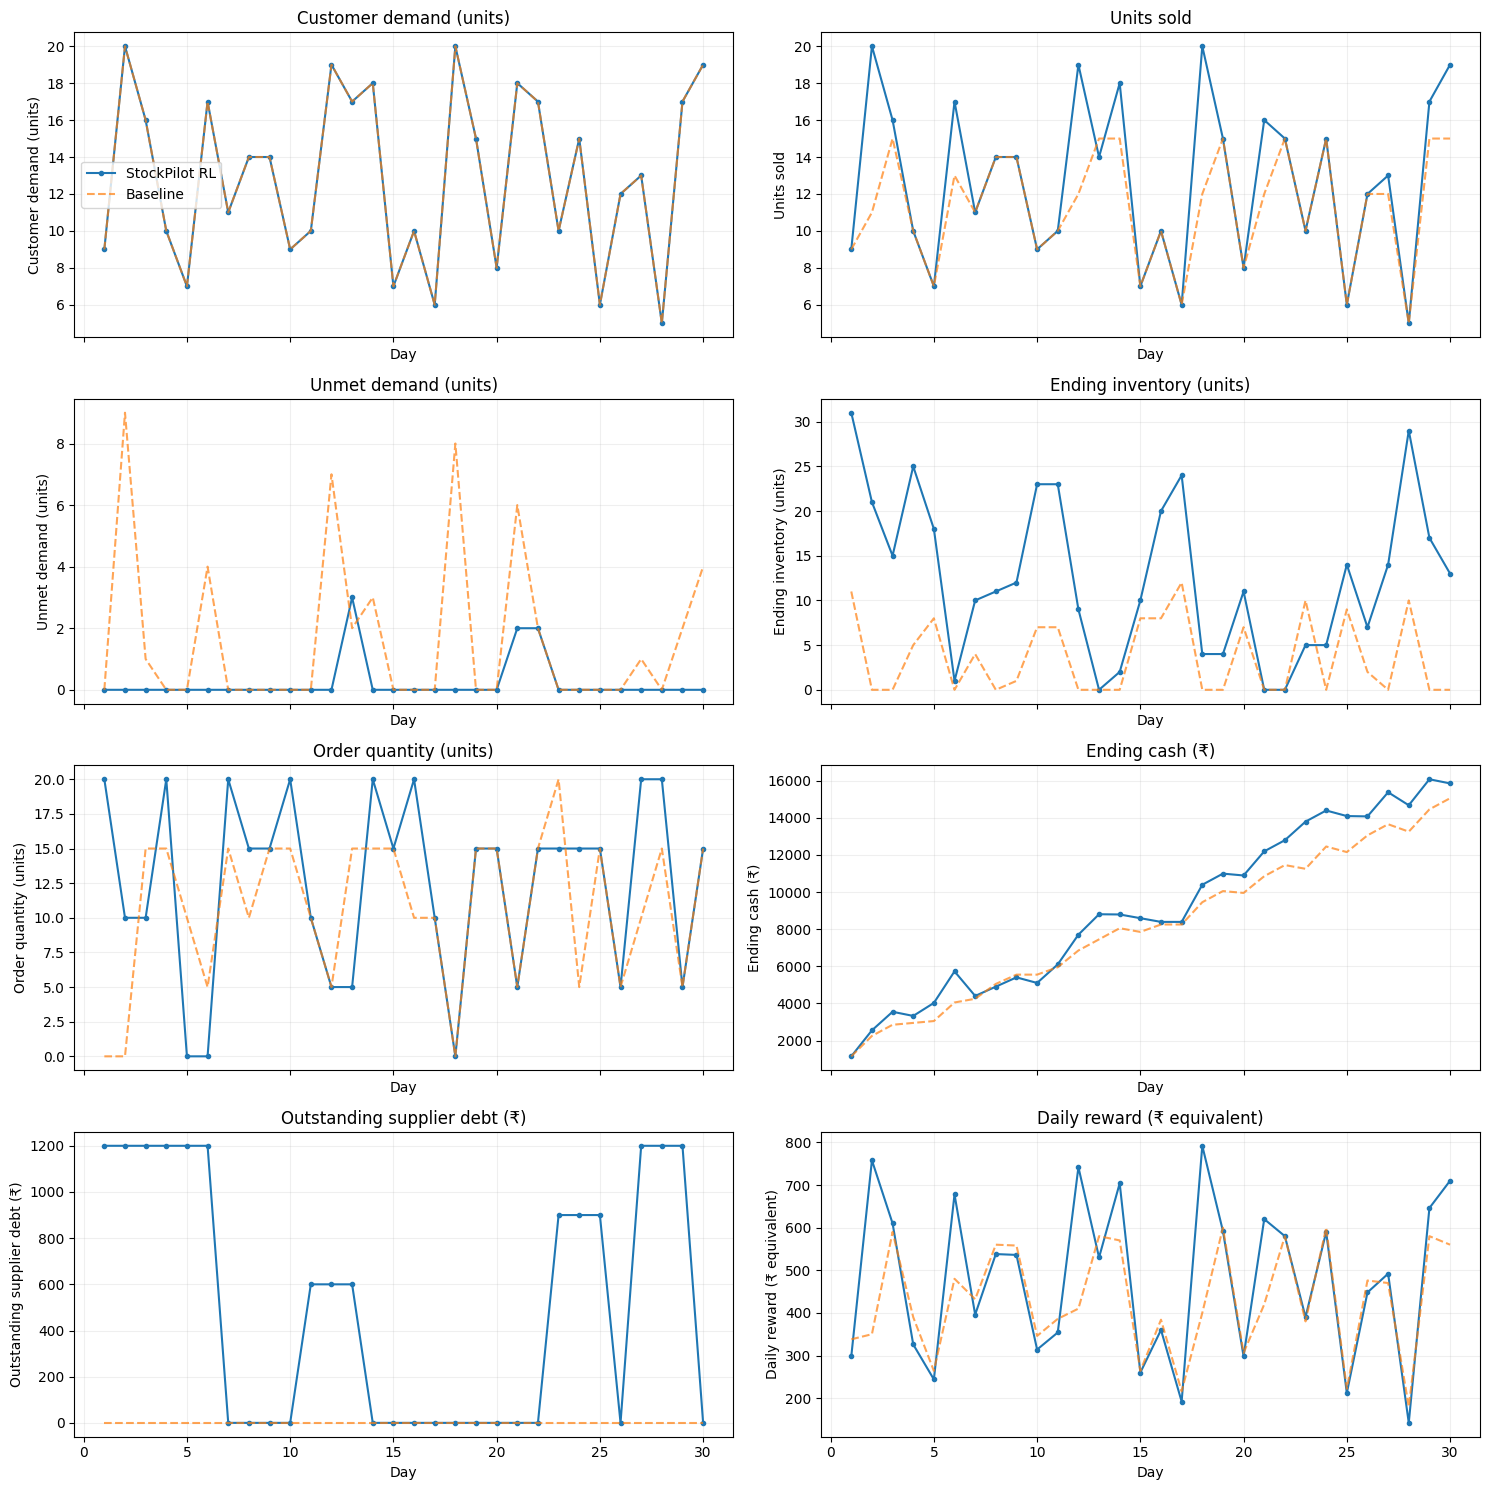

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(15, 15), sharex=True)
days = rl_results.Day
pairs = [('Demand','Customer demand (units)'), ('Sold','Units sold'),
         ('Unmet','Unmet demand (units)'), ('Inventory','Ending inventory (units)'),
         ('Order','Order quantity (units)'), ('Cash','Ending cash (₹)'),
         ('Debt','Outstanding supplier debt (₹)'), ('Reward','Daily reward (₹ equivalent)')]
for ax, (column, label) in zip(axes.flat, pairs):
    ax.plot(days, rl_results[column], marker='.', label='StockPilot RL')
    ax.plot(days, baseline_results[column], linestyle='--', alpha=.7, label='Baseline')
    ax.set(title=label, xlabel='Day', ylabel=label)
    ax.grid(alpha=.2)
axes.flat[0].legend()
plt.tight_layout(); plt.show()

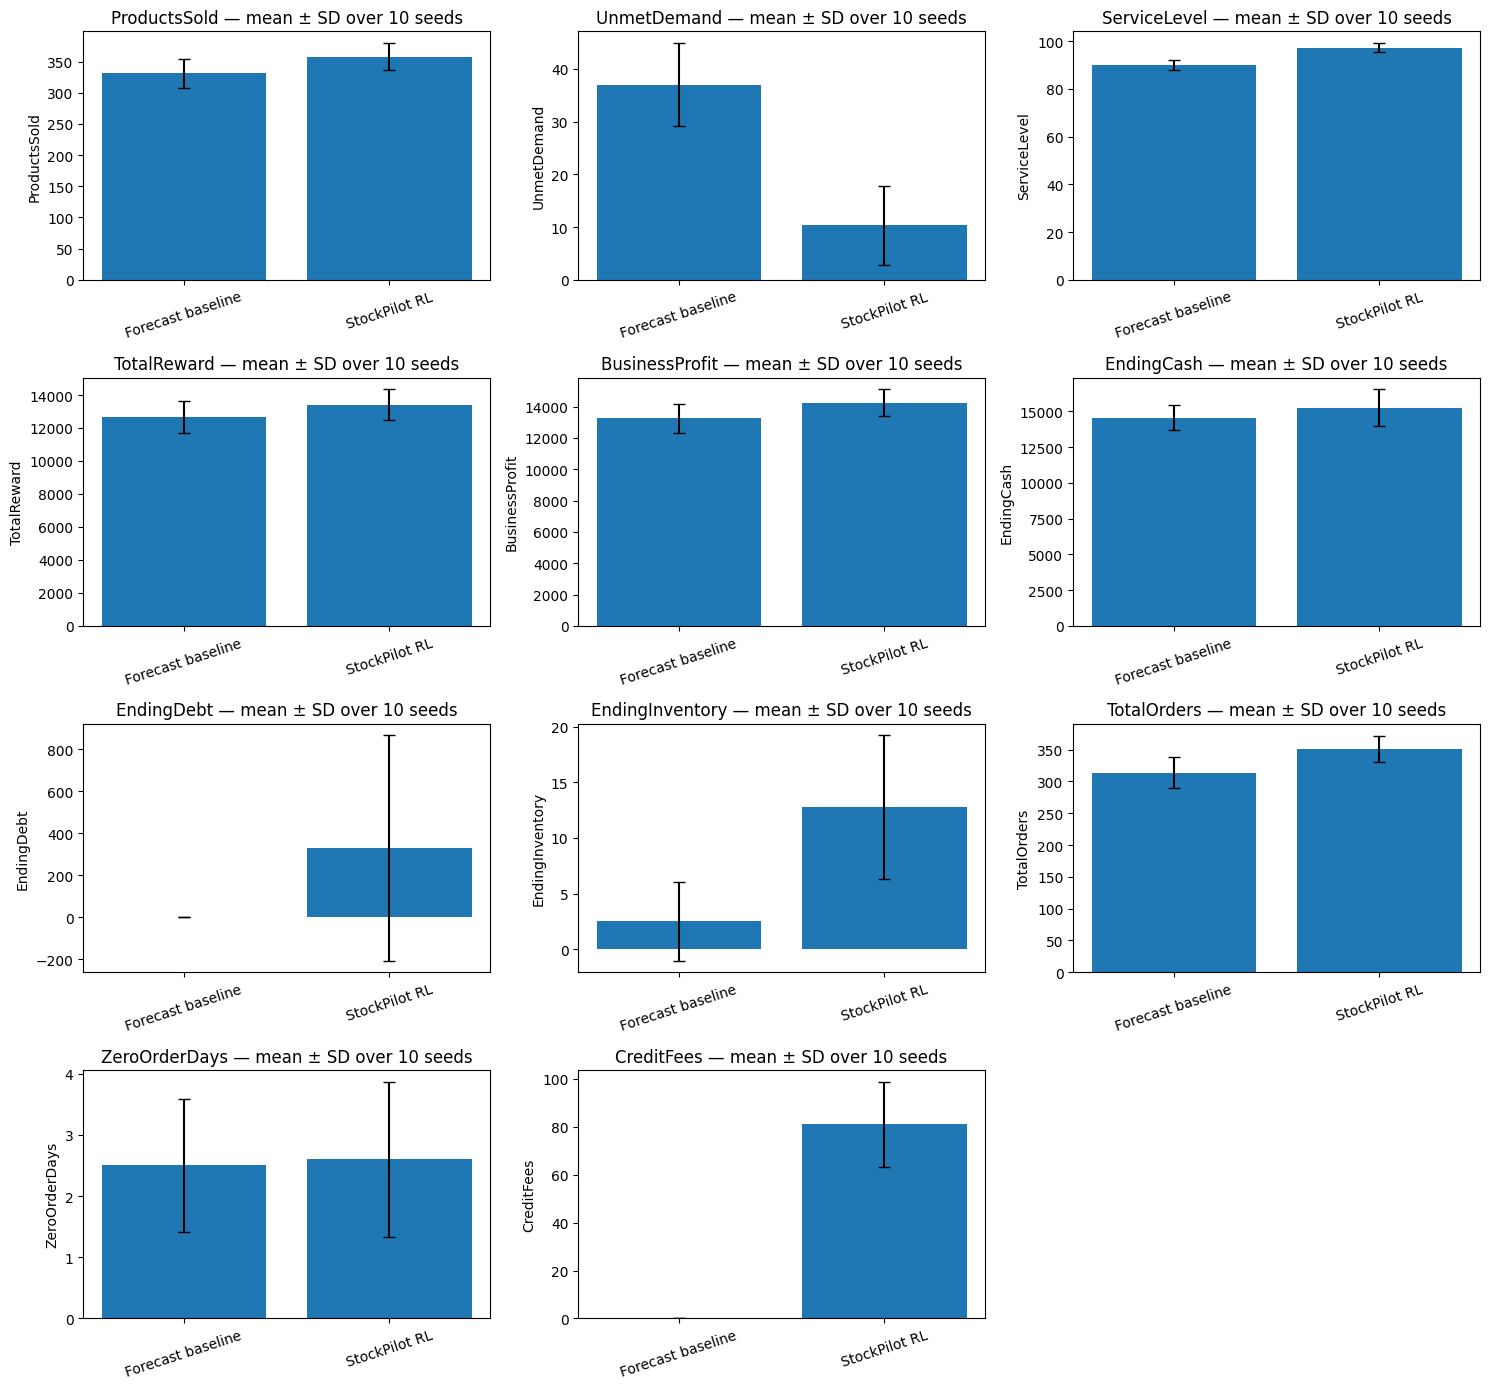

In [ ]:
metrics = ['ProductsSold','UnmetDemand','ServiceLevel','TotalReward','BusinessProfit','EndingCash',
           'EndingDebt','EndingInventory','TotalOrders','ZeroOrderDays','CreditFees']
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, metric in zip(axes.flat, metrics):
    means = results_by_seed.groupby('Policy')[metric].mean()
    errors = results_by_seed.groupby('Policy')[metric].std().fillna(0)
    ax.bar(means.index, means.values, yerr=errors.values, capsize=4)
    ax.set(title=f'{metric} — mean ± SD over {len(EVAL_SEEDS)} seeds', ylabel=metric)
    ax.tick_params(axis='x', rotation=18)
for ax in list(axes.flat)[len(metrics):]: ax.axis('off')
plt.tight_layout(); plt.show()

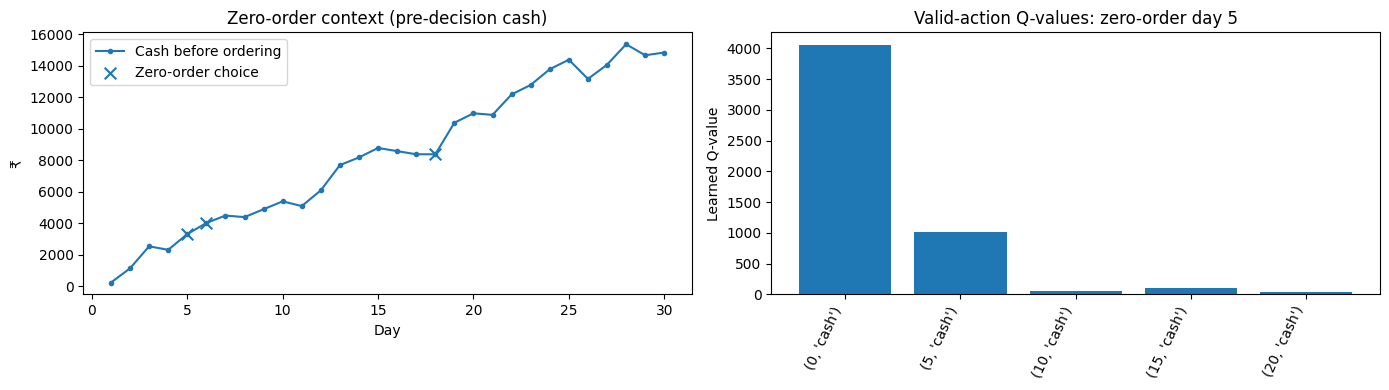

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(rl_results.Day, rl_results.CashBefore, label='Cash before ordering', marker='.')
zeros = rl_results[rl_results.Order == 0]
axes[0].scatter(zeros.Day, zeros.CashBefore, label='Zero-order choice', s=70, marker='x')
axes[0].set(title='Zero-order context (pre-decision cash)', xlabel='Day', ylabel='₹')
axes[0].legend()
# Show Q-values of the actually legal choices at a zero-order state, or first state otherwise.
if len(zero_order_audit):
    row = zero_order_audit.iloc[0]
    labels, values = list(row.QValues.keys()), list(row.QValues.values())
    axes[1].set_title(f'Valid-action Q-values: zero-order day {row.Day}')
else:
    state = int(rl_results.StateIndex.iloc[0]); valid = get_valid_actions(250,0)
    labels = [str(ACTION_OPTIONS[a]) for a in valid]
    values = [float(q_table[state,a]) for a in valid]
    axes[1].set_title('Valid-action Q-values: first state (no zero-order days)')
axes[1].bar(range(len(labels)), values)
axes[1].set_xticks(range(len(labels)), labels, rotation=65, ha='right')
axes[1].set_ylabel('Learned Q-value')
plt.tight_layout(); plt.show()

## 9 — Decision flow diagram
```text
Beginning-of-day business state (inventory, cash, debt, loan age)
        ↓  Mature/repay previous supplier loan if possible
Available cash/debt BEFORE the ordering decision
        ↓  Predict demand from past observations only
Encode state (inventory, predicted demand, cash, debt) → Q-table row
        ↓  Enumerate legal cash and credit orders
Training: epsilon-greedy / Evaluation: greedy masked Q-values
        ↓  Buy selected quantity → see actual demand → sell products
        ↓  Calculate new cash, inventory, debt and 1-time fees
        ↓  Profit = change in cash + inventory cost value − debt
        ↓  Reward = profit − holding penalty − stockout penalty
        ↓  Training only: update Q(s,a) with valid future actions
        ↓  Next day
```

### Execution guide
1. Run imports and business settings.
2. Run state encoding, action rules and the shared transition.
3. Run policy selection and the tests; fix any assertion before proceeding.
4. Run the fresh training cell; it saves a versioned configuration beside the notebook.
5. Run the held-out evaluation and zero-order audit.
6. Run the chart cells to see measured training and business performance.

### Change log from original notebook
- Consolidated multiple `simulate_day`/`simulate_business_day`, `get_state`, `run_policy` and evaluation definitions into consistent, audited functions.
- Retained **1,960×10** Q-table and order/payment mapping while disallowing duplicate zero-order credit choice.
- Added one-time maturity credit fee, safe repayment checks and no invalid purchase execution.
- Matched training/evaluation information timing and masked next-action Q update.
- Replaced inconsistent profit estimators with exact equity-change bookkeeping plus explicit noncash service penalties.
- Added fixed-seed held-out comparisons, complete decision-time zero-order diagnostics, assertions, reproducible plots and safe model-config persistence.

### Limitations / assumptions
- Synthetic uniformly sampled daily demand 5–20 is much simpler than real retail demand; a five-day mean may not capture seasonality.
- Cash/debt/inventory buckets compress many distinct states; the loan's age and whether its fee was assessed are **not** explicitly in Q-learning state, so this is a partially observed system. A future revision could encode loan age, but that would require a larger table and full retraining.
- A loan is singular, new credit requires zero existing debt, and 2% is assessed once at maturity; no cascading interest or default policy is modeled.
- The initial 20 inventory units are valued at ₹60 per unit; unsold terminal inventory has full cost salvage and is not automatically liquidated for cash.
- Holding and lost-demand penalties influence the RL objective but are **not** actual cash expenses; distinguish reward from equity profit.
- Tabular Q-learning is stochastic and may not beat the baseline. Compare the measured table, not an assumed improvement. Train with additional independent seeds and a larger holdout before making performance claims.
- No transaction timing, spoilage, capacity limits, taxes, supplier delays, inflation, or real bank-credit compliance is modeled.
